# ML Assignment 2 — Student Dropout & Academic Success Classification

**Dataset:** UCI *Predict Students' Dropout and Academic Success* (id 697) — 4,424 students, 36 features, 3 classes
(`Dropout`, `Enrolled`, `Graduate`).

This notebook:
1. loads and cleans the dataset,
2. splits it into train / test (stratified 80 / 20),
3. trains 5 classifiers (Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, SVM),
4. evaluates each on the held-out test set (Accuracy, AUC, Precision, Recall, F1, MCC),
5. saves every trained pipeline to `model/` and the test split to `test_data.csv` for the Streamlit app.

In [1]:
import io
import json
import os
import urllib.request
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, matthews_corrcoef,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

SEED = 42
TEST_FRACTION = 0.20
MODEL_DIR = Path("model")
UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.7.2 | pandas 2.3.3 | numpy 2.3.5


## 1. Load the dataset
Uses a local `data.csv` (or `data/data.csv`) if present, otherwise downloads it from the UCI repository.

In [2]:
def load_student_data():
    for candidate in [Path("data.csv"), Path("data") / "data.csv"]:
        if candidate.exists():
            print("Reading", candidate)
            return pd.read_csv(candidate, sep=";", encoding="utf-8-sig")
    print("Local file not found, downloading from UCI ...")
    with urllib.request.urlopen(UCI_ZIP_URL, timeout=60) as resp:
        archive = zipfile.ZipFile(io.BytesIO(resp.read()))
    with archive.open("data.csv") as fh:
        return pd.read_csv(fh, sep=";", encoding="utf-8-sig")


raw = load_student_data()
# the source file has a stray tab in one header and a Portuguese spelling in another
raw.columns = [c.strip() for c in raw.columns]
raw = raw.rename(columns={"Nacionality": "Nationality"})

print("Shape:", raw.shape)
raw.head()

Reading data/data.csv
Shape: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nationality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 2. Quick look at the data

Features: 36 | Instances: 4424
Missing values: 0
Duplicate rows: 0

          count  share
Target                
Graduate   2209  0.499
Dropout    1421  0.321
Enrolled    794  0.179


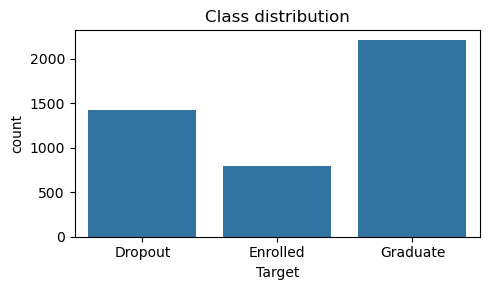

In [3]:
TARGET = "Target"
feature_cols = [c for c in raw.columns if c != TARGET]

print("Features:", len(feature_cols), "| Instances:", len(raw))
print("Missing values:", int(raw.isna().sum().sum()))
print("Duplicate rows:", int(raw.duplicated().sum()))
print()
print(raw[TARGET].value_counts().to_frame("count").assign(share=lambda d: (d["count"] / len(raw)).round(3)))

fig, ax = plt.subplots(figsize=(5, 3))
sns.countplot(x=TARGET, data=raw, order=["Dropout", "Enrolled", "Graduate"], ax=ax)
ax.set_title("Class distribution")
plt.tight_layout()
plt.show()

## 3. Preprocessing

Most columns are integer *codes* (course, nationality, parents' occupation, ...). Treating those as numbers would
invent an order that does not exist, so they are one-hot encoded. Rare codes (< 10 students) are grouped together so
the encoders stay small. The remaining columns are genuinely numeric (grades, ages, unit counts, economic indicators)
and are standardised.

Binary 0/1 flags (gender, scholarship holder, debtor, ...) are left in the numeric group — scaling a 0/1 column is
harmless.

Each model is wrapped in a `Pipeline(preprocess → classifier)`, so the saved `.pkl` contains the fitted encoder and
scaler too, and the Streamlit app can feed the raw test CSV straight into it.

In [4]:
nominal_cols = [
    "Marital status", "Application mode", "Course", "Previous qualification", "Nationality",
    "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation",
]
numeric_cols = [c for c in feature_cols if c not in nominal_cols]

CLASS_NAMES = ["Dropout", "Enrolled", "Graduate"]
label_to_id = {name: i for i, name in enumerate(CLASS_NAMES)}

X = raw[feature_cols]
y = raw[TARGET].map(label_to_id)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_FRACTION, stratify=y, random_state=SEED
)
print("Train:", X_train.shape, "| Test:", X_test.shape)


def make_preprocessor():
    return ColumnTransformer([
        ("codes", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False),
         nominal_cols),
        ("numbers", StandardScaler(), numeric_cols),
    ])

Train: (3539, 36) | Test: (885, 36)


## 4. The five classifiers

| Model | Setting | Why |
|---|---|---|
| Logistic Regression | multinomial, `C=1.0` | linear baseline, gives calibrated probabilities |
| Decision Tree | `max_depth=7`, `min_samples_leaf=10` | depth cap stops the tree memorising the training set |
| KNN | `k=15`, distance-weighted | odd-sized neighbourhood big enough to smooth noise |
| Naive Bayes | `GaussianNB`, `var_smoothing=0.1` | one-hot columns are almost constant inside a class, so their fitted variance is ~0 and a single 1 blows up the likelihood; the larger smoothing adds a variance floor (default `1e-9` gave ~28 % accuracy) |
| SVM | RBF kernel, `C=1.0`, `probability=True` | probabilities are needed for AUC |

In [5]:
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=3000, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=7, min_samples_leaf=10, random_state=SEED),
    "KNN": KNeighborsClassifier(n_neighbors=15, weights="distance"),
    "Naive Bayes": GaussianNB(var_smoothing=0.1),
    "Support Vector Machine": SVC(kernel="rbf", C=1.0, probability=True, random_state=SEED),
}

fitted = {}
for name, clf in classifiers.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", clf)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    print(f"trained  {name}")

trained  Logistic Regression
trained  Decision Tree


trained  KNN
trained  Naive Bayes


trained  Support Vector Machine


## 5. Evaluation on the test set

This is a 3-class problem, so:
- **AUC** is one-vs-rest, weighted by class size,
- **Precision / Recall / F1** are weighted averages over the three classes,
- **MCC** uses the multi-class generalisation built into scikit-learn.

In [6]:
def score_model(model, X_eval, y_eval):
    pred = model.predict(X_eval)
    proba = model.predict_proba(X_eval)
    return {
        "Accuracy": accuracy_score(y_eval, pred),
        "AUC": roc_auc_score(y_eval, proba, multi_class="ovr", average="weighted"),
        "Precision": precision_score(y_eval, pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_eval, pred, average="weighted", zero_division=0),
        "F1": f1_score(y_eval, pred, average="weighted", zero_division=0),
        "MCC": matthews_corrcoef(y_eval, pred),
    }


results = pd.DataFrame({name: score_model(m, X_test, y_test) for name, m in fitted.items()}).T.round(4)
results.index.name = "ML Model Name"
results

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.7740,0.8996,0.7612,0.7740,0.7636,0.6253
Decision Tree,0.7333,0.8685,0.7374,0.7333,0.7333,0.5649
KNN,0.7232,0.8548,0.7136,0.7232,0.6997,0.5403
Naive Bayes,0.6893,0.8302,0.6881,0.6893,0.6853,0.4879
Support Vector Machine,0.7582,0.8988,0.7459,0.7582,0.7460,0.5986


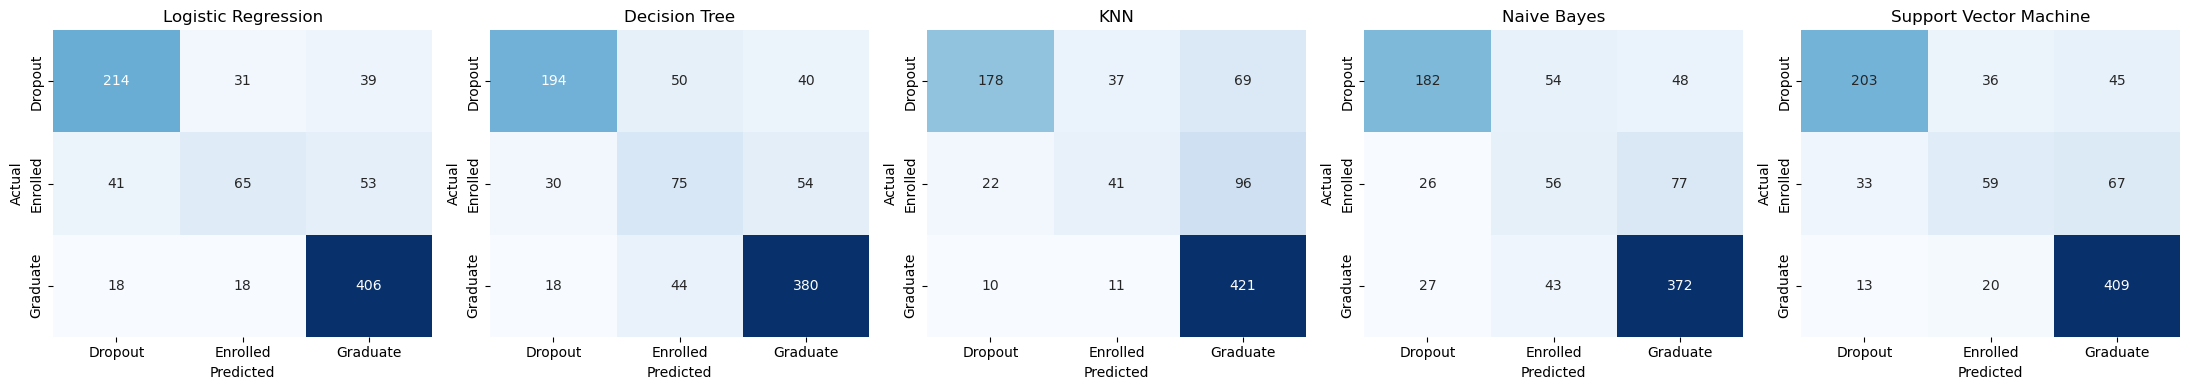

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, model) in zip(axes, fitted.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

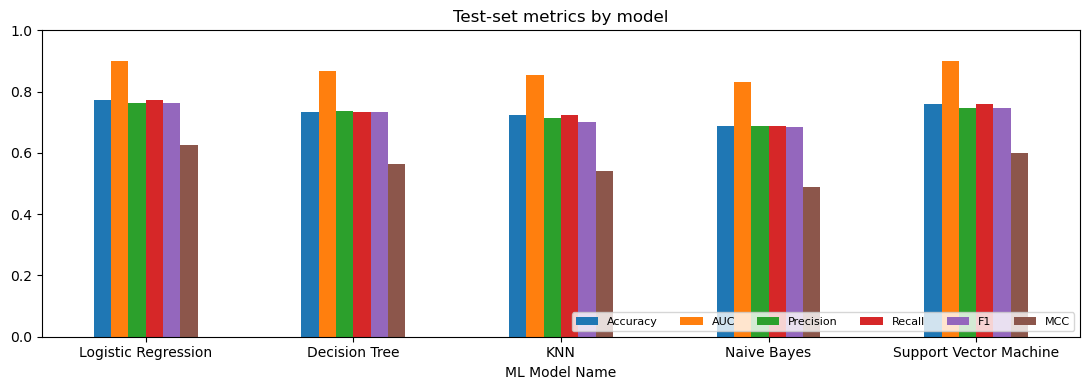

Best model by weighted F1: Logistic Regression  (F1 = 0.7636, MCC = 0.6253)


In [8]:
ax = results.plot(kind="bar", figsize=(11, 4), ylim=(0, 1), rot=0)
ax.set_title("Test-set metrics by model")
ax.legend(loc="lower right", ncol=6, fontsize=8)
plt.tight_layout()
plt.show()

best = results["F1"].idxmax()
print(f"Best model by weighted F1: {best}  (F1 = {results.loc[best, 'F1']:.4f}, MCC = {results.loc[best, 'MCC']:.4f})")

## 6. Save the models, the test split and the metadata the app needs

In [9]:
MODEL_DIR.mkdir(exist_ok=True)
file_names = {}
for name, model in fitted.items():
    file_name = name.lower().replace(" ", "_") + ".pkl"
    joblib.dump(model, MODEL_DIR / file_name)
    file_names[name] = file_name

# test split with the original text labels, exactly what gets uploaded to the app
test_df = X_test.copy()
test_df[TARGET] = y_test.map(dict(enumerate(CLASS_NAMES)))
test_df.to_csv("test_data.csv", index=False)

results.to_csv(MODEL_DIR / "test_metrics.csv")
with open(MODEL_DIR / "metadata.json", "w") as fh:
    json.dump({
        "dataset": "UCI Predict Students' Dropout and Academic Success (id 697)",
        "target": TARGET,
        "class_names": CLASS_NAMES,
        "feature_columns": feature_cols,
        "nominal_columns": nominal_cols,
        "models": file_names,
        "random_state": SEED,
        "test_fraction": TEST_FRACTION,
        "sklearn_version": sklearn.__version__,
    }, fh, indent=2)

print("Saved:", sorted(os.listdir(MODEL_DIR)))
print("test_data.csv rows:", len(test_df))

Saved: ['decision_tree.pkl', 'knn.pkl', 'logistic_regression.pkl', 'metadata.json', 'naive_bayes.pkl', 'support_vector_machine.pkl', 'test_metrics.csv']
test_data.csv rows: 885


## 7. Final comparison table

In [10]:
results

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.7740,0.8996,0.7612,0.7740,0.7636,0.6253
Decision Tree,0.7333,0.8685,0.7374,0.7333,0.7333,0.5649
KNN,0.7232,0.8548,0.7136,0.7232,0.6997,0.5403
Naive Bayes,0.6893,0.8302,0.6881,0.6893,0.6853,0.4879
Support Vector Machine,0.7582,0.8988,0.7459,0.7582,0.7460,0.5986
